# Part 1: Load Transformed Data

This first part of the notebook is responsible for setting up the environment. It executes the previous data processing and econometric analysis notebooks to load the `transformed_data` dictionary into memory. This dictionary contains the stationary time series required for the VAR analysis.

In [1]:
%run ./2_data_processing.ipynb


Loading cached data for National...
Loading cached data for SF...
Loading cached data for DET...
Loading cached data for ATL...
Loading cached data for LV...
\nData loading complete.
\nSample of raw data for SF:
             indpro    cpi  fedfunds        hpi  unemp      permits
date                                                               
1991-01-01  61.0842  134.7      6.91  71.935495    4.6  2037.040992
1991-02-01  60.6387  134.8      6.25  71.126390    4.7   585.889721
1991-03-01  60.2973  134.8      6.12  70.608208    4.9   835.829789
1991-04-01  60.4524  135.1      5.91  69.909268    5.0   789.687733
1991-05-01  61.0587  135.6      5.78  70.010559    5.1   625.659862
Processed 'indpro' (raw and log-difference).
Processed 'cpi' (raw and log-difference).
Processed 'fedfunds' (raw and first-difference).
Processed 'permits' for all areas (raw and log-difference).
Processed 'unemp' for all areas (raw and first-difference).
Processed 'hpi' for all areas (raw and log-difference).


# Part 2: Reusable Functions

To ensure the analysis is clean, readable, and maintainable, this section defines two core functions:

1.  `evaluate_lag_criteria`: This function takes a DataFrame of time series and systematically calculates the optimal lag length according to three different information criteria: AIC, BIC, and HQIC. It returns a dictionary containing the optimal lag for each criterion.
2.  `assemble_area_data`: This function is responsible for constructing the correctly ordered DataFrame for a specific geographic area. It takes the area name, the `transformed_data` dictionary, and the Cholesky variable order as inputs, and returns a clean, non-null DataFrame ready for modeling.

In [2]:
from statsmodels.tsa.api import VAR
import pandas as pd

def evaluate_lag_criteria(data: pd.DataFrame, maxlags: int = 15):
    """
    Evaluates and returns the optimal lag length for AIC, BIC, and HQIC.
    Args:
        data (pd.DataFrame): Time series data for VAR.
        maxlags (int): Maximum lags to consider.
    Returns:
        dict: {criterion: optimal_lag}
    """
    model = VAR(data)
    results = {}
    for ic in ['aic', 'bic', 'hqic']:
        try:
            results[ic] = model.fit(maxlags=maxlags, ic=ic).k_ar
        except Exception:
            results[ic] = None
    return results


In [3]:

def assemble_area_data(area: str, transformed_data: dict, cholesky_order: list) -> pd.DataFrame:
    """
    Assembles a DataFrame for a specific area in the correct Cholesky order.
    Args:
        area (str): Area name (e.g., 'SF', 'National').
        transformed_data (dict): Dictionary of all time series.
        cholesky_order (list): List of variable names in order.
    Returns:
        pd.DataFrame: Cleaned DataFrame for modeling.
    """
    model_data = {}
    for var in cholesky_order:
        # Check if the data for the variable is a DataFrame (multi-area)
        if isinstance(transformed_data[var], pd.DataFrame):
            # If it's a DataFrame, select the column corresponding to the area
            if area in transformed_data[var].columns:
                model_data[var] = transformed_data[var][area]
        # If it's a Series (single, national-level data), use it directly
        elif isinstance(transformed_data[var], pd.Series):
            model_data[var] = transformed_data[var]

    # Create DataFrame and explicitly set column order to ensure it matches Cholesky order
    df = pd.DataFrame(model_data)
    
    # Ensure all columns from cholesky_order are present before reindexing
    present_columns = [col for col in cholesky_order if col in df.columns]
    
    df_ordered = df[present_columns].dropna()
    
    # Set the frequency of the index to 'MS' (Month Start) to avoid warnings
    df_ordered.index.freq = 'MS'
    
    return df_ordered

# Part 3: Lag Length Analysis

This section applies the reusable functions to each geographic area. For each area, it assembles the data in Cholesky order and evaluates the optimal lag length using AIC, BIC, and HQIC. The results are presented in a summary table for easy comparison.

In [4]:
# Define areas and Cholesky order
areas = ['National', 'SF', 'DET', 'ATL', 'LV']
cholesky_order = [
    'indpro_log_diff', 'cpi_log_diff', 'fedfunds_diff',
    'permits_log_diff', 'unemp_diff', 'hpi_log_diff'
]

# Evaluate lag criteria for each area
lag_results = {}
for area in areas:
    df = assemble_area_data(area, transformed_data, cholesky_order)
    if df.empty:
        lag_results[area] = {'aic': None, 'bic': None, 'hqic': None}
    else:
        lag_results[area] = evaluate_lag_criteria(df)

# Create and display results table
results_df = pd.DataFrame(lag_results).T[['aic', 'bic', 'hqic']]
results_df = results_df.T
results_df.index.name = 'Criterion'
display(results_df)

,National,SF,DET,ATL,LV
Criterion,,,,,
aic,3,2,4,2,2
bic,1,1,1,1,1
hqic,1,2,1,2,2


# Part 4: Fit VAR(1) Models

Based on the lag length analysis, particularly the BIC results, a lag length of 1 is chosen for all areas. This section fits a VAR(1) model to each geographic area's time series data.

In [5]:
# Hardcode lag length
lag_length = 1

# Fit VAR(1) model for each area
var_models = {}
for area in areas:
    df = assemble_area_data(area, transformed_data, cholesky_order)
    if not df.empty:
        model = VAR(df)
        var_models[area] = model.fit(lag_length)

# Display a summary for one of the models to verify
if 'National' in var_models:
    print("--- VAR(1) Model Summary for National Area ---")
    display(var_models['National'].summary())

--- VAR(1) Model Summary for National Area ---


  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Mon, 22, Sep, 2025
Time:                     13:08:48
--------------------------------------------------------------------
No. of Equations:         6.00000    BIC:                   -49.9106
Nobs:                     202.000    HQIC:                  -50.3201
Log likelihood:           3432.69    FPE:                1.06035e-22
AIC:                     -50.5984    Det(Omega_mle):     8.64328e-23
--------------------------------------------------------------------
Results for equation indpro_log_diff
                         coefficient       std. error           t-stat            prob
--------------------------------------------------------------------------------------
const                       0.003667         0.000644            5.693           0.000
L1.indpro_log_diff         -0.088384         0.073177           -1.208           0.227
L1.cpi_log_diff           

In [6]:
import pickle

# Save the var_models dictionary to a file for use in other notebooks
with open('var_models.pkl', 'wb') as f:
    pickle.dump(var_models, f)

print("VAR models saved to var_models.pkl")

VAR models saved to var_models.pkl


# Part 5: Granger Causality Analysis

This section investigates the causal relationships between the variables in our VAR models. We define a reusable function to perform Granger causality tests and then apply it to each area's model to see which variables have a statistically significant impact on house price growth (`hpi_log_diff`).

In [7]:

def perform_granger_causality(model_fit, caused_var: str):
    """
    Performs Granger causality tests on a fitted VAR model.

    Args:
        model_fit: A fitted VAR model result from statsmodels.
        caused_var (str): The variable that is being caused (the dependent variable).

    Returns:
        dict: A dictionary with variable names as keys and their p-values as values.
    """
    causality_results = {}
    # Iterate over the endogenous variables, not the exogenous ones
    for var in model_fit.names:
        if var != caused_var:
            # The 'causing' variable must be a list
            test_result = model_fit.test_causality(caused=caused_var, causing=[var], kind='f')
            causality_results[var] = test_result.pvalue
    return causality_results

# Run the analysis for each area
granger_results = {}
for area, model_fit in var_models.items():
    granger_results[area] = perform_granger_causality(model_fit, 'hpi_log_diff')

# Display the results in a DataFrame
granger_df = pd.DataFrame(granger_results).T
granger_df.index.name = 'Area'
print("--- Granger Causality p-values for hpi_log_diff ---")
display(granger_df)

# Save the DataFrame to a CSV file
granger_df.to_csv('granger_causality_results.csv')
print("\nResults saved to granger_causality_results.csv")


--- Granger Causality p-values for hpi_log_diff ---


,indpro_log_diff,cpi_log_diff,fedfunds_diff,permits_log_diff,unemp_diff
Area,,,,,
National,0.443390,0.576283,0.748405,0.345340,0.770877
SF,0.035707,0.355273,0.152013,0.365105,0.228448
DET,0.323887,0.894354,0.527929,0.751568,0.543823
ATL,0.037794,0.325080,0.028361,0.339169,0.407784
LV,0.508468,0.945127,0.277310,0.577831,0.011232



Results saved to granger_causality_results.csv


##### "A preliminary Granger causality analysis shows that the simple, atheoretical predictors of house price growth vary significantly across regions and are often statistically insignificant. This highlights the need to move beyond mere statistical prediction and employ a structural model to identify the consistent, underlying causal transmission mechanism of monetary policy." - Gemini

# Our model

$$
\begin{pmatrix}
    \text{dln\_INDPRO}_t \\
    \text{dln\_CPI}_t \\
    \text{d\_FFR}_t \\
    \text{dln\_PERMITS}_t \\
    \text{d\_UNEMP}_t \\
    \text{dln\_HPI}_t
\end{pmatrix}
=
\begin{pmatrix}
    c_1 \\ c_2 \\ c_3 \\ c_4 \\ c_5 \\ c_6
\end{pmatrix}
+
\begin{pmatrix}
    a_{11} & a_{12} & \dots & a_{16} \\
    a_{21} & a_{22} & \dots & a_{26} \\
    \vdots & \vdots & \ddots & \vdots \\
    a_{61} & a_{62} & \dots & a_{66}
\end{pmatrix}
\begin{pmatrix}
    \text{dln\_INDPRO}_{t-1} \\
    \text{dln\_CPI}_{t-1} \\
    \text{d\_FFR}_{t-1} \\
    \text{dln\_PERMITS}_{t-1} \\
    \text{d\_UNEMP}_{t-1} \\
    \text{dln\_HPI}_{t-1}
\end{pmatrix}
+
\begin{pmatrix}
    e_{1,t} \\ e_{2,t} \\ \vdots \\ e_{6,t}
\end{pmatrix}
$$

# Cholensky

$$
\underbrace{
\begin{pmatrix}
1 & 0 & 0 & 0 & 0 & 0 \\
a_{21} & 1 & 0 & 0 & 0 & 0 \\
a_{31} & a_{32} & 1 & 0 & 0 & 0 \\
a_{41} & a_{42} & a_{43} & 1 & 0 & 0 \\
a_{51} & a_{52} & a_{53} & a_{54} & 1 & 0 \\
a_{61} & a_{62} & a_{63} & a_{64} & a_{65} & 1
\end{pmatrix}
}_{\mathbf{A}}
\underbrace{
\begin{pmatrix} \epsilon_t^{\text{INDPRO}} \\ \epsilon_t^{\text{CPI}} \\ \epsilon_t^{\text{FFR}} \\ \epsilon_t^{\text{PERMITS}} \\ \epsilon_t^{\text{UNEMP}} \\ \epsilon_t^{\text{HPI}} \end{pmatrix}
}_{\boldsymbol{\epsilon_t}}
=
\underbrace{
\begin{pmatrix} u_t^{\text{INDPRO}} \\ u_t^{\text{CPI}} \\ u_t^{\text{FFR}} \\ u_t^{\text{PERMITS}} \\ u_t^{\text{UNEMP}} \\ u_t^{\text{HPI}} \end{pmatrix}
}_{\mathbf{u_t}}
$$

In [8]:
cholesky_order = [
    'indpro_log_diff', 'cpi_log_diff', 'fedfunds_diff',
    'permits_log_diff', 'unemp_diff', 'hpi_log_diff'
]

sf = assemble_area_data('SF', transformed_data, cholesky_order)

# Fit VAR(1) model for SF area
sf_model = VAR(sf).fit(1)
print("--- VAR(1) Model Summary for SF Area ---")
display(sf_model.summary())



--- VAR(1) Model Summary for SF Area ---


  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Mon, 22, Sep, 2025
Time:                     13:08:48
--------------------------------------------------------------------
No. of Equations:         6.00000    BIC:                   -44.7417
Nobs:                     202.000    HQIC:                  -45.1512
Log likelihood:           2910.63    FPE:                1.86328e-20
AIC:                     -45.4295    Det(Omega_mle):     1.51883e-20
--------------------------------------------------------------------
Results for equation indpro_log_diff
                         coefficient       std. error           t-stat            prob
--------------------------------------------------------------------------------------
const                       0.002967         0.000571            5.196           0.000
L1.indpro_log_diff         -0.064704         0.070569           -0.917           0.359
L1.cpi_log_diff           

--- Impulse Responses for SF to a 'fedfunds_diff' Shock ---


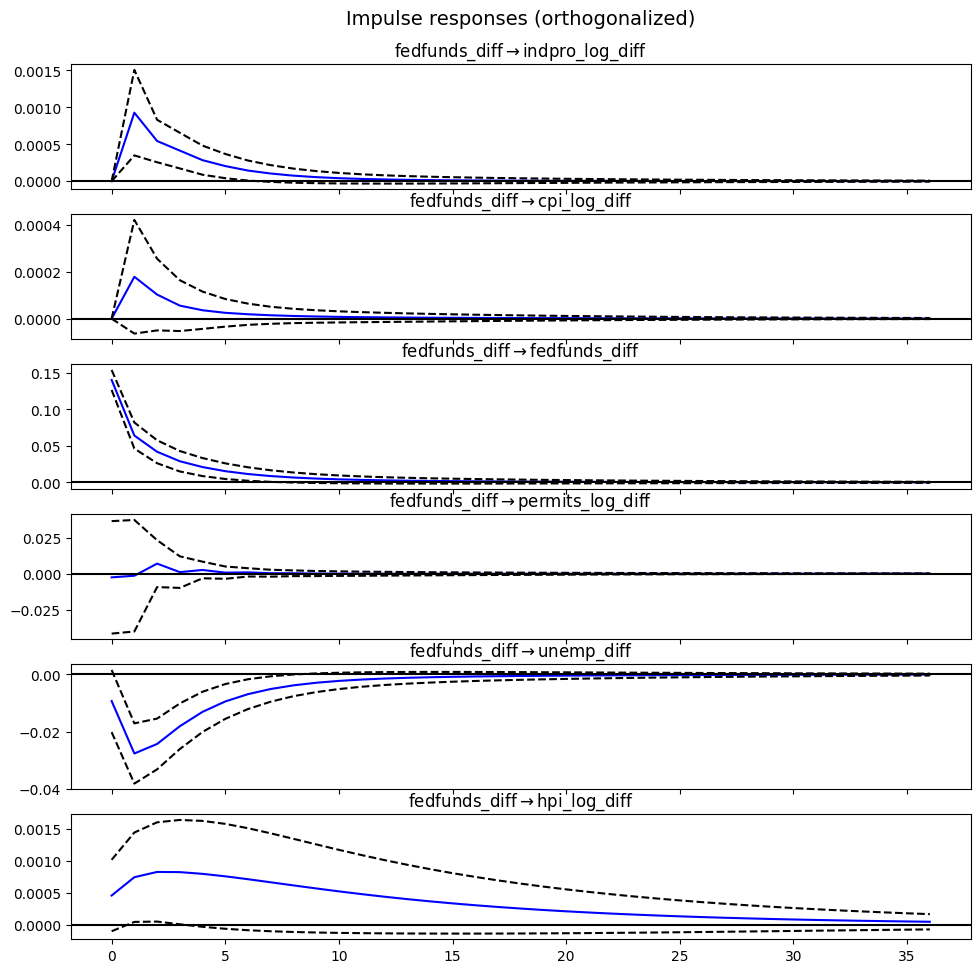


--- Impulse Responses of HPI to All Shocks in SF ---


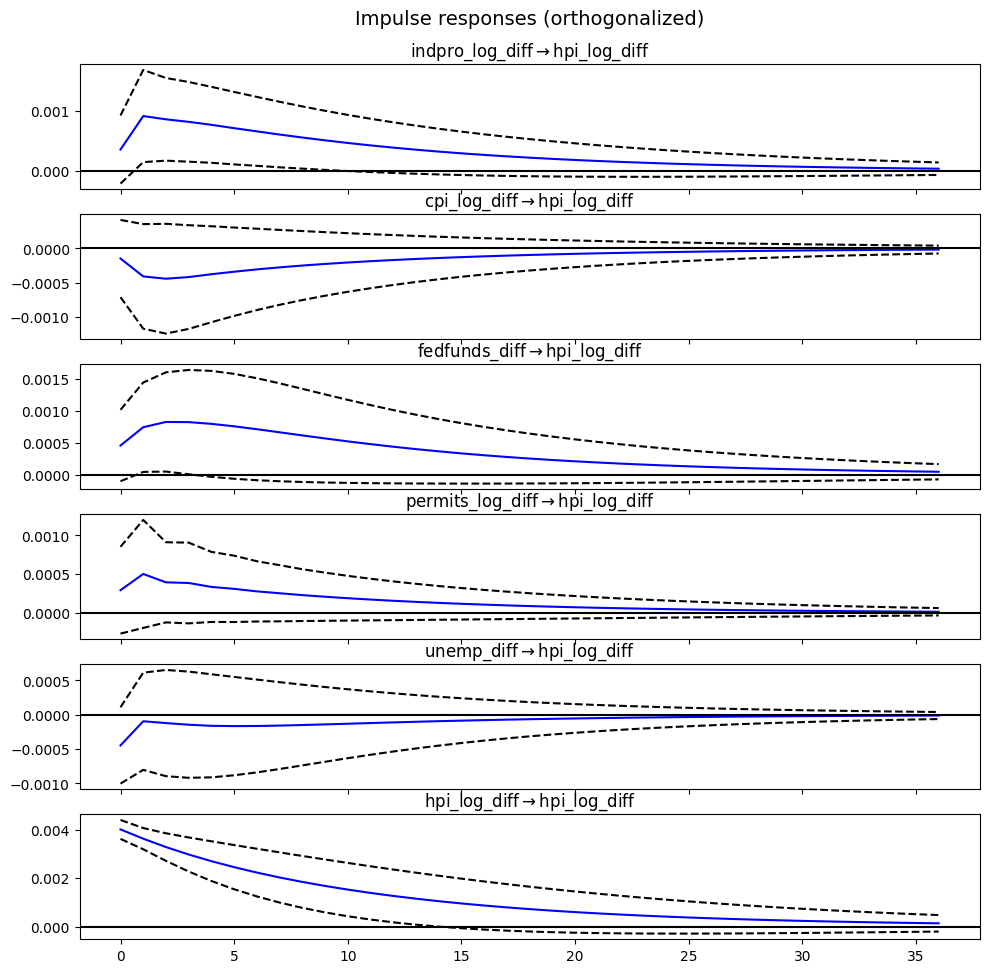


--- Saving IRF Numeric Data ---
Saved responses to 'fedfunds_diff' shock to irf_sf_to_fedfunds_shock.csv
Saved responses of 'hpi_log_diff' to all shocks to irf_hpi_to_all_shocks.csv


In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Calculate Impulse Response Functions (IRF) for the SF model
# We'll look at a 36-month horizon
n_periods = 36
irf_sf = sf_model.irf(periods=n_periods)

# --- Plotting ---
# Plot the impulse responses of all variables to a shock in 'fedfunds_diff'
print("--- Impulse Responses for SF to a 'fedfunds_diff' Shock ---")
fig = irf_sf.plot(impulse='fedfunds_diff', response=None, orth=True, signif=0.05)
plt.show()

# Plot the impulse responses of 'hpi_log_diff' to shocks in all variables
print("\n--- Impulse Responses of HPI to All Shocks in SF ---")
fig = irf_sf.plot(impulse=None, response='hpi_log_diff', orth=True, signif=0.05)
plt.show()

# --- Saving Numeric Data ---
print("\n--- Saving IRF Numeric Data ---")

# 1. Extract and save responses of all variables to a 'fedfunds_diff' shock
impulse_var = 'fedfunds_diff'
impulse_idx = sf_model.names.index(impulse_var)
response_vars = sf_model.names

# Create a multi-index for columns to store value, lower, and upper bounds
cols = pd.MultiIndex.from_product([response_vars, ['irf', 'lower_ci', 'upper_ci']], names=['variable', 'metric'])
irf_data_ff_shock = pd.DataFrame(columns=cols, index=range(n_periods + 1))

for i, var in enumerate(response_vars):
    irf_vals = irf_sf.orth_irfs[:, impulse_idx, i]
    stderr_vals = irf_sf.stderr()[:, impulse_idx, i]
    irf_data_ff_shock[(var, 'irf')] = irf_vals
    irf_data_ff_shock[(var, 'lower_ci')] = irf_vals - 1.96 * stderr_vals
    irf_data_ff_shock[(var, 'upper_ci')] = irf_vals + 1.96 * stderr_vals

irf_data_ff_shock.index.name = 'period'
irf_ff_shock_filename = 'irf_sf_to_fedfunds_shock.csv'
irf_data_ff_shock.to_csv(irf_ff_shock_filename)
print(f"Saved responses to '{impulse_var}' shock to {irf_ff_shock_filename}")


# 2. Extract and save responses of 'hpi_log_diff' to all shocks
response_var = 'hpi_log_diff'
response_idx = sf_model.names.index(response_var)
impulse_vars = sf_model.names

cols_hpi = pd.MultiIndex.from_product([impulse_vars, ['irf', 'lower_ci', 'upper_ci']], names=['shock_variable', 'metric'])
irf_data_hpi = pd.DataFrame(columns=cols_hpi, index=range(n_periods + 1))

for i, var in enumerate(impulse_vars):
    irf_vals = irf_sf.orth_irfs[:, i, response_idx]
    stderr_vals = irf_sf.stderr()[:, i, response_idx]
    irf_data_hpi[(var, 'irf')] = irf_vals
    irf_data_hpi[(var, 'lower_ci')] = irf_vals - 1.96 * stderr_vals
    irf_data_hpi[(var, 'upper_ci')] = irf_vals + 1.96 * stderr_vals

irf_data_hpi.index.name = 'period'
irf_hpi_filename = 'irf_hpi_to_all_shocks.csv'
irf_data_hpi.to_csv(irf_hpi_filename)
print(f"Saved responses of '{response_var}' to all shocks to {irf_hpi_filename}")

# Part 8: Reusable Functions for Systematic IRF Analysis

To make the analysis scalable and repeatable, this section introduces reusable functions for plotting and saving IRF results. These functions will then be used to process all geographic areas in a loop.

In [10]:
import os

def save_irf_data(model_fit, area_name: str, n_periods: int):
    """
    Calculates and saves the numeric IRF data for a given area to CSV files.

    Args:
        model_fit: A fitted VAR model result from statsmodels.
        area_name (str): The name of the geographic area (e.g., 'SF').
        n_periods (int): The number of periods for the IRF calculation.
    """
    print(f"--- Saving IRF Data for {area_name} ---")
    
    # Create a directory for the data if it doesn't exist
    data_dir = 'irf_data'
    os.makedirs(data_dir, exist_ok=True)
    
    irf = model_fit.irf(periods=n_periods)
    
    # 1. Extract and save responses of all variables to a 'fedfunds_diff' shock
    impulse_var = 'fedfunds_diff'
    if impulse_var not in model_fit.names:
        print(f"'{impulse_var}' not in model for {area_name}. Skipping that IRF save.")
        return

    impulse_idx = model_fit.names.index(impulse_var)
    response_vars = model_fit.names

    cols = pd.MultiIndex.from_product([response_vars, ['irf', 'lower_ci', 'upper_ci']], names=['variable', 'metric'])
    irf_data_shock = pd.DataFrame(columns=cols, index=range(n_periods + 1))

    for i, var in enumerate(response_vars):
        irf_vals = irf.orth_irfs[:, impulse_idx, i]
        stderr_vals = irf.stderr()[:, impulse_idx, i]
        irf_data_shock[(var, 'irf')] = irf_vals
        irf_data_shock[(var, 'lower_ci')] = irf_vals - 1.96 * stderr_vals
        irf_data_shock[(var, 'upper_ci')] = irf_vals + 1.96 * stderr_vals

    irf_data_shock.index.name = 'period'
    filename_shock = os.path.join(data_dir, f'{area_name}_responses_to_{impulse_var}_shock.csv')
    irf_data_shock.to_csv(filename_shock)
    print(f"Saved responses to '{impulse_var}' shock to {filename_shock}")

    # 2. Extract and save responses of 'hpi_log_diff' to all shocks
    response_var = 'hpi_log_diff'
    if response_var not in model_fit.names:
        print(f"'{response_var}' not in model for {area_name}. Skipping that IRF save.")
        return
        
    response_idx = model_fit.names.index(response_var)
    impulse_vars = model_fit.names

    cols_hpi = pd.MultiIndex.from_product([impulse_vars, ['irf', 'lower_ci', 'upper_ci']], names=['shock_variable', 'metric'])
    irf_data_response = pd.DataFrame(columns=cols_hpi, index=range(n_periods + 1))

    for i, var in enumerate(impulse_vars):
        irf_vals = irf.orth_irfs[:, i, response_idx]
        stderr_vals = irf.stderr()[:, i, response_idx]
        irf_data_response[(var, 'irf')] = irf_vals
        irf_data_response[(var, 'lower_ci')] = irf_vals - 1.96 * stderr_vals
        irf_data_response[(var, 'upper_ci')] = irf_vals + 1.96 * stderr_vals

    irf_data_response.index.name = 'period'
    filename_response = os.path.join(data_dir, f'{area_name}_{response_var}_responses_to_all_shocks.csv')
    irf_data_response.to_csv(filename_response)
    print(f"Saved responses of '{response_var}' to all shocks to {filename_response}")

# Part 9: Loop Through All Areas for IRF Analysis

Now, we'll use the reusable functions to systematically generate and save the IRF plots and data for every geographic area in our study.

In [11]:
# Define the horizon for the impulse responses
n_periods_loop = 36

# Loop through each area's fitted model
for area, model_fit in var_models.items():
    # Save the numeric IRF data to CSV files
    save_irf_data(model_fit, area, n_periods_loop)
    
    print(f"\n{'='*50}\n") # Separator for clarity

print("Completed IRF data saving for all areas.")

--- Saving IRF Data for National ---
Saved responses to 'fedfunds_diff' shock to irf_data\National_responses_to_fedfunds_diff_shock.csv
Saved responses of 'hpi_log_diff' to all shocks to irf_data\National_hpi_log_diff_responses_to_all_shocks.csv


--- Saving IRF Data for SF ---
Saved responses to 'fedfunds_diff' shock to irf_data\SF_responses_to_fedfunds_diff_shock.csv
Saved responses of 'hpi_log_diff' to all shocks to irf_data\SF_hpi_log_diff_responses_to_all_shocks.csv


--- Saving IRF Data for DET ---
Saved responses to 'fedfunds_diff' shock to irf_data\DET_responses_to_fedfunds_diff_shock.csv
Saved responses of 'hpi_log_diff' to all shocks to irf_data\DET_hpi_log_diff_responses_to_all_shocks.csv


--- Saving IRF Data for ATL ---
Saved responses to 'fedfunds_diff' shock to irf_data\DET_responses_to_fedfunds_diff_shock.csv
Saved responses of 'hpi_log_diff' to all shocks to irf_data\DET_hpi_log_diff_responses_to_all_shocks.csv


--- Saving IRF Data for ATL ---
Saved responses to 'fedf